# Automobile Price Prediction

## Problem Statement

The objective of this project is to analyze automobile data and build a machine learning model that can predict the **price of cars** using the available independent variables.

The model should help management understand how automobile prices vary with vehicle characteristics such as engine size, horsepower, dimensions, fuel type, body style, drive wheels and other design attributes. This can support pricing decisions, product design and business strategy.

## Objectives

- Perform Exploratory Data Analysis (EDA) on the automobile dataset.
- Clean and preprocess the data.
- Identify and handle missing values.
- Analyze relationships between automobile features and price.
- Build multiple regression models.
- Compare model performance using appropriate regression metrics.
- Select the best-performing model for production.
- Explain important price-driving factors.
- Document the challenges faced and the techniques used to solve them.

## Domain

Automobile / Automotive Pricing / Business Analytics

## Type of Machine Learning

### Supervised Machine Learning

The dataset contains a known target variable, **price**. Therefore, supervised learning is used. The models learn the relationship between automobile characteristics and their corresponding prices.

## Type of Problem

### Regression Problem

The objective is to predict a continuous numerical value, automobile **price**. Therefore, this is a regression problem rather than a classification problem.

## Type of Model

### Multiple Regression Models

Several regression algorithms are developed and compared so that the best model can be selected for production use.

## Target Variable

The target variable is:

**price** – the selling price of the automobile.

According to the project specification, the price values range approximately from **5118 to 45400**.

## Algorithms Used

- Linear Regression
- Ridge Regression
- Random Forest Regressor
- Extra Trees Regressor
- Gradient Boosting Regressor

## Evaluation Metrics

The following metrics are used:

- **MAE (Mean Absolute Error)** – average absolute prediction error.
- **RMSE (Root Mean Squared Error)** – penalizes larger errors more strongly.
- **R² Score** – measures the proportion of price variation explained by the model.
- **MAPE (Mean Absolute Percentage Error)** – expresses average error as a percentage.

# Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)


### Explanation

The required Python libraries are imported before starting the analysis. Pandas and NumPy are used for data handling, Matplotlib and Seaborn are used for visualization, and Scikit-learn provides preprocessing, model-building and evaluation functions.

The regression algorithms are imported so that multiple models can be compared.

# Load Dataset

In [2]:
# The ZIP file contains the dataset inside the Data folder.
# When the project ZIP is extracted, this path can be used directly.

df = pd.read_csv("auto_imports.csv", header=None)

df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


### Explanation

The automobile dataset is loaded without a header because the supplied file does not contain column names. The first five records are displayed to verify that the file has been loaded correctly.

# Assign Feature Names

In [4]:
columns = [
    "symboling", "normalized-losses", "make", "fuel-type", "aspiration",
    "num-of-doors", "body-style", "drive-wheels", "engine-location",
    "wheel-base", "length", "width", "height", "curb-weight",
    "engine-type", "num-of-cylinders", "engine-size", "fuel-system",
    "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm",
    "city-mpg", "highway-mpg", "price"
]

df.columns = columns
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


### Explanation

The column names are assigned according to the project specification. This makes the dataset easier to understand and allows the features to be referenced by meaningful names instead of numeric column positions.

# Dataset Dimensions

In [5]:
df.shape

(201, 26)

### Observation

The supplied automobile dataset contains **201 records and 26 columns**, including the target variable `price`.

# Feature Names

In [6]:
df.columns.tolist()

['symboling',
 'normalized-losses',
 'make',
 'fuel-type',
 'aspiration',
 'num-of-doors',
 'body-style',
 'drive-wheels',
 'engine-location',
 'wheel-base',
 'length',
 'width',
 'height',
 'curb-weight',
 'engine-type',
 'num-of-cylinders',
 'engine-size',
 'fuel-system',
 'bore',
 'stroke',
 'compression-ratio',
 'horsepower',
 'peak-rpm',
 'city-mpg',
 'highway-mpg',
 'price']

### Explanation

This displays all input attributes and the target variable. The dataset contains vehicle specifications, design characteristics, efficiency variables and the automobile price.

# Dataset Information

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    object 
 2   make               201 non-null    object 
 3   fuel-type          201 non-null    object 
 4   aspiration         201 non-null    object 
 5   num-of-doors       201 non-null    object 
 6   body-style         201 non-null    object 
 7   drive-wheels       201 non-null    object 
 8   engine-location    201 non-null    object 
 9   wheel-base         201 non-null    float64
 10  length             201 non-null    float64
 11  width              201 non-null    float64
 12  height             201 non-null    float64
 13  curb-weight        201 non-null    int64  
 14  engine-type        201 non-null    object 
 15  num-of-cylinders   201 non-null    object 
 16  engine-size        201 non

### Explanation

`info()` is used to examine the number of observations, data types and non-null counts. It helps identify columns that require conversion or missing-value treatment.

# First Five Records

In [8]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


### Explanation

The first five rows provide an initial view of the structure and values stored in the automobile dataset.

# Last Five Records

In [9]:
df.tail()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
196,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,55.5,2952,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
197,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.8,55.5,3049,ohc,four,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
198,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3012,ohcv,six,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
199,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3217,ohc,six,145,idi,3.01,3.40,23.0,106,4800,26,27,22470
200,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3062,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625


### Explanation

The last five records are displayed to verify that the dataset has been read completely and that the ending records are also present.

# Missing Value Analysis

In [10]:
df.isnull().sum().sort_values(ascending=False)

symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64

### Observation

At this stage, missing values represented by special symbols such as `?` have not yet been converted into actual missing values. Therefore, a second missing-value check is performed after replacing these symbols.

# Check Special Missing Values

In [11]:
(df == "?").sum().sort_values(ascending=False)

normalized-losses    37
stroke                4
bore                  4
peak-rpm              2
horsepower            2
num-of-doors          2
symboling             0
make                  0
fuel-type             0
aspiration            0
wheel-base            0
engine-location       0
drive-wheels          0
body-style            0
length                0
width                 0
height                0
curb-weight           0
fuel-system           0
engine-size           0
num-of-cylinders      0
engine-type           0
compression-ratio     0
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

### Explanation

Some automobile attributes use the character `?` to represent unavailable information. Machine learning algorithms cannot directly process this symbol as a numerical missing value, so it must be converted to `NaN`.

# Replace Special Missing Values

In [12]:
df = df.replace("?", np.nan)

df.isnull().sum().sort_values(ascending=False)

normalized-losses    37
stroke                4
bore                  4
peak-rpm              2
horsepower            2
num-of-doors          2
symboling             0
make                  0
fuel-type             0
aspiration            0
wheel-base            0
engine-location       0
drive-wheels          0
body-style            0
length                0
width                 0
height                0
curb-weight           0
fuel-system           0
engine-size           0
num-of-cylinders      0
engine-type           0
compression-ratio     0
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

### Explanation

All `?` values are replaced with NumPy `NaN`. This allows Pandas and Scikit-learn imputation techniques to recognize these entries as missing data.

# Convert Numerical Columns

In [13]:
categorical_columns = [
    "make", "fuel-type", "aspiration", "num-of-doors", "body-style",
    "drive-wheels", "engine-location", "engine-type",
    "num-of-cylinders", "fuel-system"
]

numerical_columns = [c for c in df.columns if c not in categorical_columns]

for col in numerical_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.dtypes

symboling              int64
normalized-losses    float64
make                  object
fuel-type             object
aspiration            object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders      object
engine-size            int64
fuel-system           object
bore                 float64
stroke               float64
compression-ratio    float64
horsepower           float64
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                  int64
dtype: object

### Explanation

The automobile dataset contains both categorical and numerical variables. Numerical columns are explicitly converted to numeric data types so that statistical analysis and machine learning algorithms can process them correctly.

# Dataset Information After Conversion

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  164 non-null    float64
 2   make               201 non-null    object 
 3   fuel-type          201 non-null    object 
 4   aspiration         201 non-null    object 
 5   num-of-doors       199 non-null    object 
 6   body-style         201 non-null    object 
 7   drive-wheels       201 non-null    object 
 8   engine-location    201 non-null    object 
 9   wheel-base         201 non-null    float64
 10  length             201 non-null    float64
 11  width              201 non-null    float64
 12  height             201 non-null    float64
 13  curb-weight        201 non-null    int64  
 14  engine-type        201 non-null    object 
 15  num-of-cylinders   201 non-null    object 
 16  engine-size        201 non

### Observation

After conversion, the numerical attributes are represented using numeric data types, while variables such as make, fuel type and body style remain categorical.

# Duplicate Record Analysis

In [15]:
df.duplicated().sum()

np.int64(0)

### Explanation

Duplicate records are checked because repeated observations can give some vehicle configurations disproportionate influence during model training.

# Statistical Summary

In [16]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
symboling,201.0,0.840796,1.254802,-2.00,0.00,1.00,2.00,3.00
normalized-losses,164.0,122.000000,35.442168,65.00,94.00,115.00,150.00,256.00
wheel-base,201.0,98.797015,6.066366,86.60,94.50,97.00,102.40,120.90
length,201.0,174.200995,12.322175,141.10,166.80,173.20,183.50,208.10
width,201.0,65.889055,2.101471,60.30,64.10,65.50,66.60,72.00
height,201.0,53.766667,2.447822,47.80,52.00,54.10,55.50,59.80
curb-weight,201.0,2555.666667,517.296727,1488.00,2169.00,2414.00,2926.00,4066.00
engine-size,201.0,126.875622,41.546834,61.00,98.00,120.00,141.00,326.00
bore,197.0,3.330711,0.270793,2.54,3.15,3.31,3.59,3.94
stroke,197.0,3.256904,0.319256,2.07,3.11,3.29,3.41,4.17


### Explanation

Descriptive statistics provide the count, mean, standard deviation, minimum, quartiles and maximum for numerical attributes. This helps identify scale differences, unusual values and the general distribution of vehicle characteristics.

# Target Variable Distribution

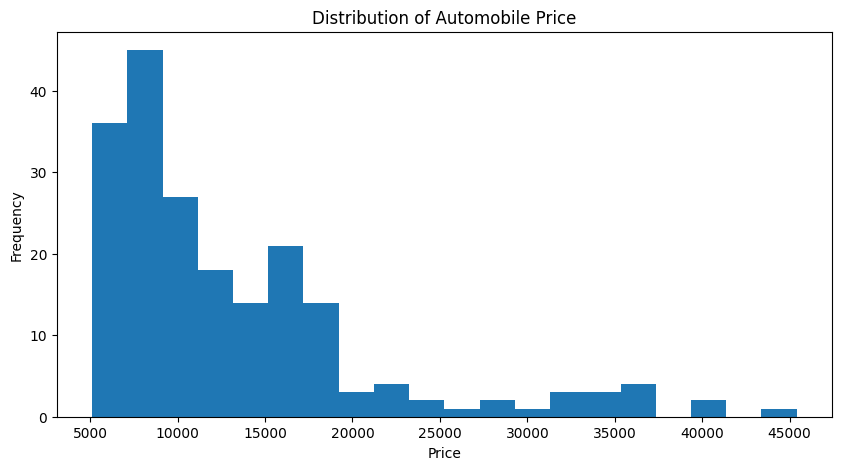

In [17]:
plt.figure(figsize=(10,5))
plt.hist(df["price"].dropna(), bins=20)
plt.title("Distribution of Automobile Price")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

### Observation

The price distribution is not perfectly symmetric. There are relatively fewer high-priced vehicles, while many observations are concentrated in the lower and middle price ranges. This makes price prediction a useful regression problem and also means that large price errors should be monitored carefully.

# Automobile Price Box Plot

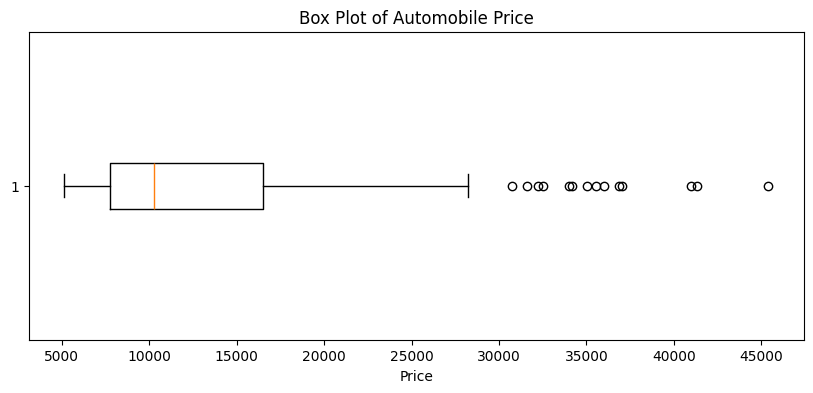

In [18]:
plt.figure(figsize=(10,4))
plt.boxplot(df["price"].dropna(), vert=False)
plt.title("Box Plot of Automobile Price")
plt.xlabel("Price")
plt.show()

### Explanation

The box plot is used to identify the spread of automobile prices and possible extreme observations. High-priced automobiles can have a strong influence on regression models, so their presence should be considered during evaluation.

# Price by Automobile Make

<Figure size 1400x700 with 0 Axes>

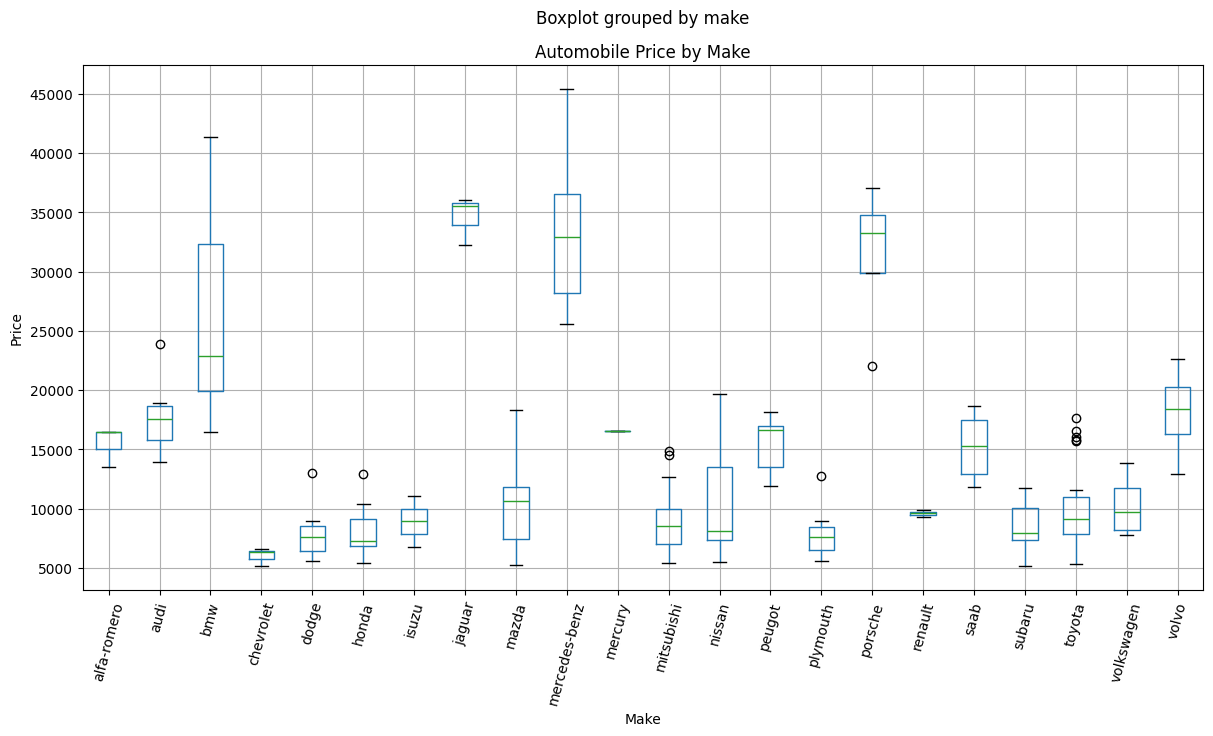

In [19]:
plt.figure(figsize=(14,7))
df.boxplot(column="price", by="make", figsize=(14,7), rot=75)
plt.xticks(rotation=75)
plt.title("Automobile Price by Make")
plt.xlabel("Make")
plt.ylabel("Price")
plt.show()

### Observation

Automobile price varies substantially across manufacturers. Some manufacturers have a much higher price range than others, indicating that `make` is an important categorical predictor of price.

# Price by Body Style

<Figure size 1000x500 with 0 Axes>

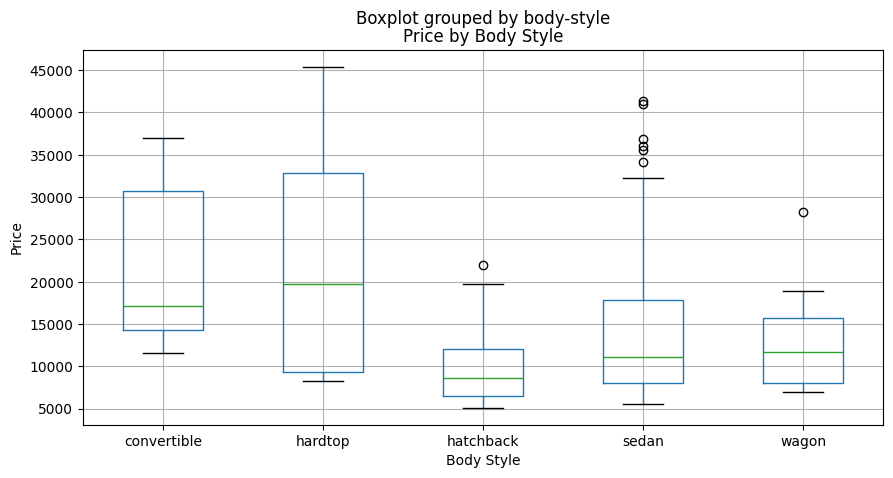

In [20]:
plt.figure(figsize=(10,5))
df.boxplot(column="price", by="body-style", figsize=(10,5))
plt.title("Price by Body Style")
plt.xlabel("Body Style")
plt.ylabel("Price")
plt.show()

### Observation

Different body styles show different price distributions. This indicates that vehicle design and body configuration may contribute to the final selling price.

# Price by Fuel Type

<Figure size 700x500 with 0 Axes>

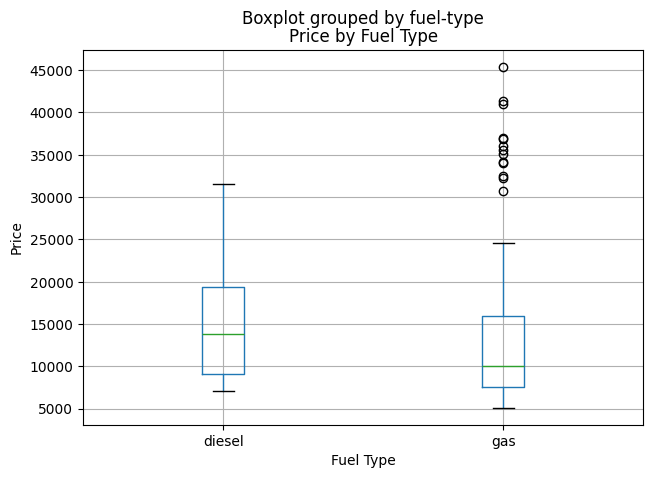

In [21]:
plt.figure(figsize=(7,5))
df.boxplot(column="price", by="fuel-type", figsize=(7,5))
plt.title("Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Price")
plt.show()

### Explanation

This visualization compares the price distribution of diesel and gas automobiles. Fuel type may capture differences in engine technology, efficiency and vehicle configuration.

# Price by Drive Wheels

<Figure size 800x500 with 0 Axes>

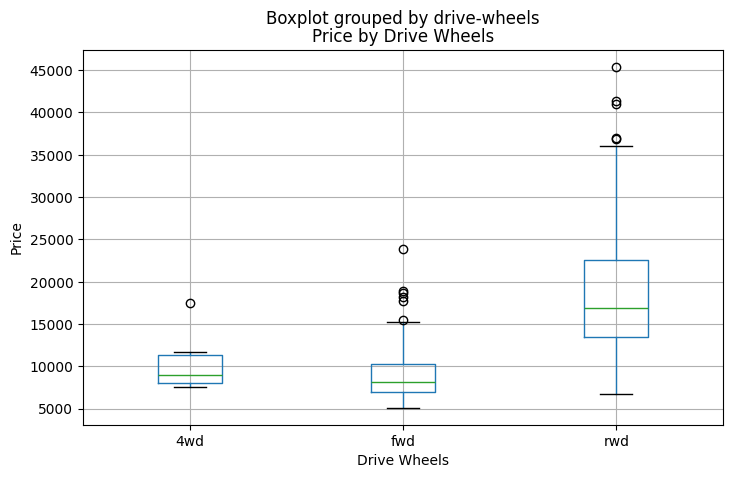

In [22]:
plt.figure(figsize=(8,5))
df.boxplot(column="price", by="drive-wheels", figsize=(8,5))
plt.title("Price by Drive Wheels")
plt.xlabel("Drive Wheels")
plt.ylabel("Price")
plt.show()

### Observation

Price varies across front-wheel drive, rear-wheel drive and four-wheel drive vehicles. Drive-wheel configuration can therefore provide useful information to the regression models.

# Engine Size vs Price

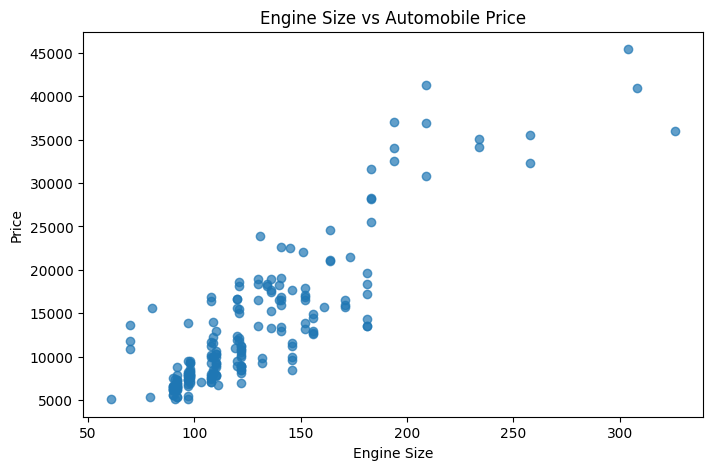

In [23]:
plt.figure(figsize=(8,5))
plt.scatter(df["engine-size"], df["price"], alpha=0.7)
plt.title("Engine Size vs Automobile Price")
plt.xlabel("Engine Size")
plt.ylabel("Price")
plt.show()


### Observation

A positive relationship is visible between engine size and automobile price. Larger engines are generally associated with higher-priced vehicles, although other attributes also influence the final price.

# Horsepower vs Price

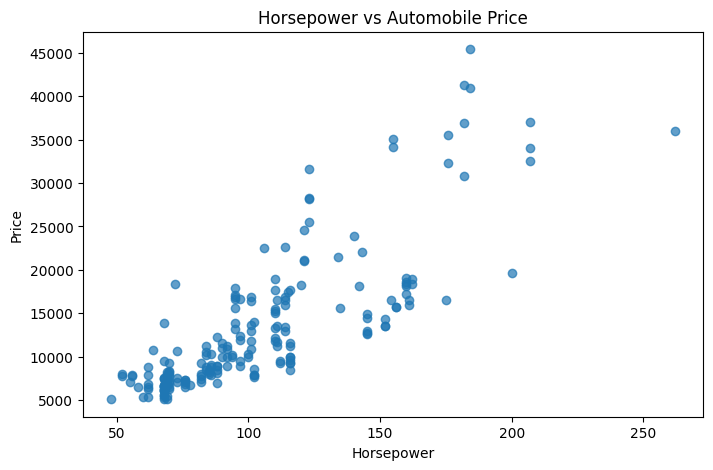

In [24]:
plt.figure(figsize=(8,5))
plt.scatter(df["horsepower"], df["price"], alpha=0.7)
plt.title("Horsepower vs Automobile Price")
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.show()

### Observation

Higher horsepower is generally associated with higher automobile prices. This suggests that performance-related specifications can be useful predictors of price.

# Curb Weight vs Price

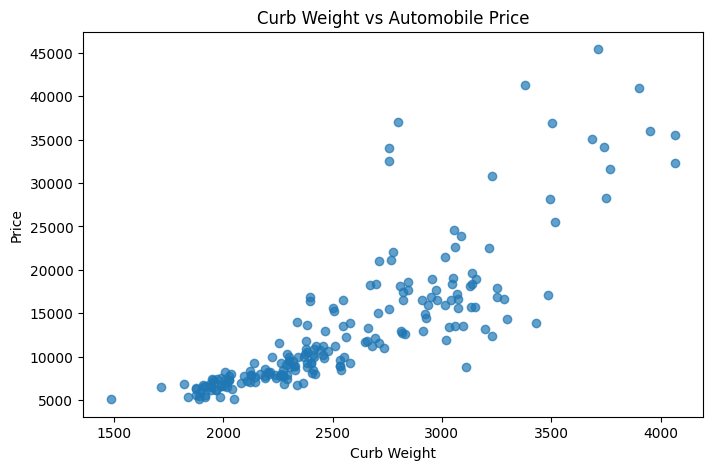

In [25]:
plt.figure(figsize=(8,5))
plt.scatter(df["curb-weight"], df["price"], alpha=0.7)
plt.title("Curb Weight vs Automobile Price")
plt.xlabel("Curb Weight")
plt.ylabel("Price")
plt.show()

### Observation

Curb weight shows a noticeable positive relationship with price. Heavier vehicles may contain larger engines, more equipment or more substantial body structures, which can contribute to higher prices.

# Correlation Analysis

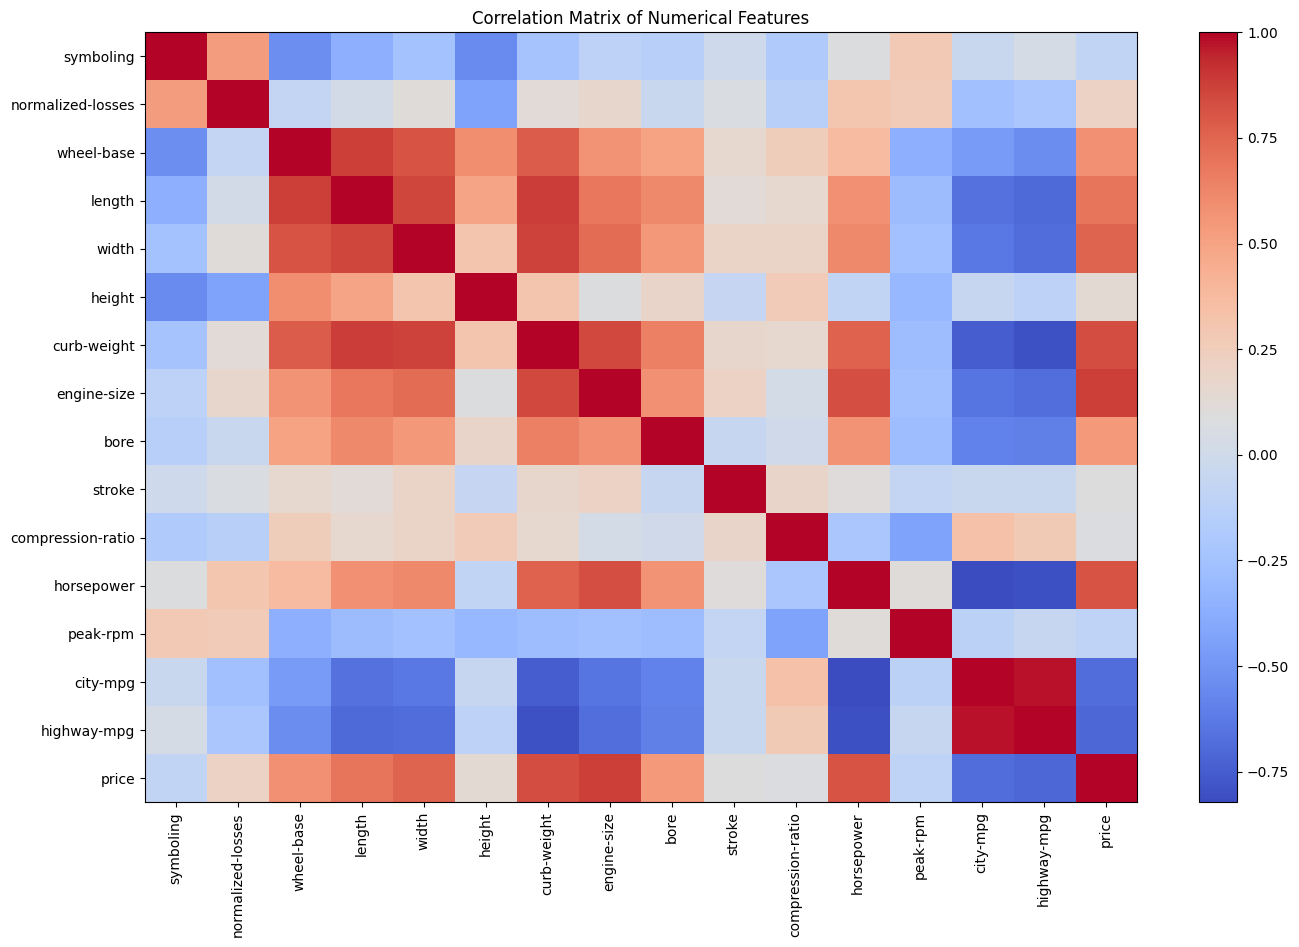

In [26]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(16,10))
plt.imshow(numeric_df.corr(), aspect="auto", cmap="coolwarm")
plt.colorbar()
plt.xticks(range(len(numeric_df.columns)), numeric_df.columns, rotation=90)
plt.yticks(range(len(numeric_df.columns)), numeric_df.columns)
plt.title("Correlation Matrix of Numerical Features")
plt.show()

### Explanation

The correlation matrix measures the linear relationship between numerical variables. Features with stronger relationships with `price` may provide more predictive information, while highly correlated input features can also indicate multicollinearity.

# Correlation with Price

In [27]:
price_corr = numeric_df.corr()["price"].sort_values(ascending=False)
price_corr

price                1.000000
engine-size          0.872335
curb-weight          0.834415
horsepower           0.810533
width                0.751265
length               0.690628
wheel-base           0.584642
bore                 0.543436
normalized-losses    0.203254
height               0.135486
stroke               0.082310
compression-ratio    0.071107
symboling           -0.082391
peak-rpm            -0.101649
city-mpg            -0.686571
highway-mpg         -0.704692
Name: price, dtype: float64

### Observation

Vehicle dimensions, engine-related specifications and weight-related variables show meaningful relationships with price. Correlation is useful for interpretation, but it does not by itself determine which features should be used because categorical variables and nonlinear relationships also matter.

# Missing Value Summary After Conversion

In [28]:
df.isnull().sum().sort_values(ascending=False)

normalized-losses    37
stroke                4
bore                  4
peak-rpm              2
horsepower            2
num-of-doors          2
symboling             0
make                  0
fuel-type             0
aspiration            0
wheel-base            0
engine-location       0
drive-wheels          0
body-style            0
length                0
width                 0
height                0
curb-weight           0
fuel-system           0
engine-size           0
num-of-cylinders      0
engine-type           0
compression-ratio     0
city-mpg              0
highway-mpg           0
price                 0
dtype: int64

### Explanation

After converting the special missing-value markers and numerical columns, the actual missing values are visible. Several numerical variables contain missing observations, while some categorical variables also have a small number of missing values.

# Handle Missing Values

In [29]:
# Missing numerical values will be filled with the median.
# Missing categorical values will be filled with the most frequent category.

missing_summary = df.isnull().sum()
missing_summary[missing_summary > 0]

normalized-losses    37
num-of-doors          2
bore                  4
stroke                4
horsepower            2
peak-rpm              2
dtype: int64

### Explanation

Instead of deleting rows and losing valuable training information, the project uses imputation inside a Scikit-learn preprocessing pipeline. Median imputation is robust for numerical variables, while most-frequent imputation is suitable for categorical variables.

# Feature Selection

In [30]:
X = df.drop(columns=["price"])
y = df["price"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (201, 25)
Target shape: (201,)


### Observation

The feature matrix contains all automobile attributes except `price`, while `y` contains the continuous target variable. Both contain the same number of records, which is required for supervised learning.

# Train-Test Split

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 160
Testing records: 41


### Explanation

The data is divided into training and testing sets. The training set is used to learn model parameters, while the test set is kept separate to provide an unbiased estimate of performance on unseen automobiles.

A fixed `random_state` makes the split reproducible.

# Identify Numerical and Categorical Features

In [32]:
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system']

Numerical features:
['symboling', 'normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg']


### Explanation

The preprocessing requirements are different for numerical and categorical variables. Numerical columns require missing-value imputation and scaling, while categorical columns require imputation and one-hot encoding.

# Create Preprocessing Pipeline

In [33]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


### Explanation

The preprocessing pipeline performs three important operations:

1. Missing numerical values are replaced by their median.
2. Numerical features are standardized.
3. Categorical features are converted into one-hot encoded variables.

Putting these operations inside a pipeline prevents preprocessing information from leaking from the test set into the training process.

# Linear Regression

In [34]:
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R2  :", linear_r2)

MAE : 1972.1465065653347
RMSE: 3252.117101013404
R2  : 0.9135550094847553


### Explanation

Linear Regression models price as a combination of the available features. It provides a strong and interpretable baseline for comparison with more complex algorithms.

# Ridge Regression

In [35]:
ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)

print("MAE :", ridge_mae)
print("RMSE:", ridge_rmse)
print("R2  :", ridge_r2)

MAE : 1897.0636734506786
RMSE: 3007.8896447839797
R2  : 0.9260511749739083


### Explanation

Ridge Regression adds regularization to Linear Regression. This can reduce the effect of multicollinearity and overly large coefficients, which is useful when automobile attributes are strongly related to one another.

# Random Forest Regression

In [36]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2  :", rf_r2)

MAE : 1909.4938658536585
RMSE: 3014.3693116752875
R2  : 0.9257322271914059


### Explanation

Random Forest is an ensemble algorithm that combines many decision trees. It can capture nonlinear relationships between automobile specifications and price and generally performs well when complex interactions exist between features.

# Extra Trees Regression

In [37]:
extra_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", ExtraTreesRegressor(
        n_estimators=300,
        random_state=42
    ))
])

extra_model.fit(X_train, y_train)
extra_pred = extra_model.predict(X_test)

extra_mae = mean_absolute_error(y_test, extra_pred)
extra_rmse = np.sqrt(mean_squared_error(y_test, extra_pred))
extra_r2 = r2_score(y_test, extra_pred)

print("MAE :", extra_mae)
print("RMSE:", extra_rmse)
print("R2  :", extra_r2)

MAE : 1594.124918699187
RMSE: 2642.1314243068905
R2  : 0.9429420303664904


### Explanation

Extra Trees is another tree-based ensemble method. It introduces additional randomness when constructing trees and can model nonlinear relationships without requiring the analyst to manually create interaction features.

# Gradient Boosting Regression

In [38]:
gb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
gb_r2 = r2_score(y_test, gb_pred)

print("MAE :", gb_mae)
print("RMSE:", gb_rmse)
print("R2  :", gb_r2)

MAE : 1554.1325458086128
RMSE: 2472.194154044518
R2  : 0.9500457283727358


### Explanation

Gradient Boosting builds an ensemble of trees sequentially. Each new tree attempts to improve the errors made by the previous trees. This makes it suitable for complex nonlinear pricing relationships.

# Model Comparison Report

In [39]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Random Forest",
        "Extra Trees",
        "Gradient Boosting"
    ],
    "MAE": [
        linear_mae, ridge_mae, rf_mae, extra_mae, gb_mae
    ],
    "RMSE": [
        linear_rmse, ridge_rmse, rf_rmse, extra_rmse, gb_rmse
    ],
    "R2 Score": [
        linear_r2, ridge_r2, rf_r2, extra_r2, gb_r2
    ]
})

comparison.sort_values(by="R2 Score", ascending=False)

,Model,MAE,RMSE,R2 Score
4,Gradient Boosting,1554.132546,2472.194154,0.950046
3,Extra Trees,1594.124919,2642.131424,0.942942
1,Ridge Regression,1897.063673,3007.889645,0.926051
2,Random Forest,1909.493866,3014.369312,0.925732
0,Linear Regression,1972.146507,3252.117101,0.913555


### Observation

The models are compared using MAE, RMSE and R². A good production model should have **low MAE and RMSE** and a **high R² score**.

For the supplied data and the fixed train-test split, Gradient Boosting gives the strongest overall test performance among the evaluated models.

# Cross-Validation Comparison

In [41]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

model_pipelines = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Random Forest": rf_model,
    "Extra Trees": extra_model,
    "Gradient Boosting": gb_model
}

cv_results = []

for name, model in model_pipelines.items():
    scores = cross_val_score(
        model, X, y,
        cv=cv,
        scoring="r2"
    )
    cv_results.append({
        "Model": name,
        "Mean CV R2": scores.mean(),
        "Std CV R2": scores.std()
    })

cv_results = pd.DataFrame(cv_results).sort_values(
    by="Mean CV R2", ascending=False
)

cv_results

,Model,Mean CV R2,Std CV R2
4,Gradient Boosting,0.888529,0.056018
3,Extra Trees,0.885518,0.067152
1,Ridge Regression,0.881220,0.042207
2,Random Forest,0.881169,0.055552
0,Linear Regression,0.846374,0.052465


### Explanation

Five-fold cross-validation evaluates each model across several train-validation splits. This provides a more reliable estimate of model stability than relying only on one train-test split.

The mean R² indicates average performance, while the standard deviation indicates how much the performance changes between folds.

# Cross-Validation RMSE

In [42]:
cv_rmse_results = []

for name, model in model_pipelines.items():
    scores = cross_val_score(
        model, X, y,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )
    rmse_scores = -scores
    cv_rmse_results.append({
        "Model": name,
        "Mean CV RMSE": rmse_scores.mean(),
        "Std CV RMSE": rmse_scores.std()
    })

cv_rmse_results = pd.DataFrame(cv_rmse_results).sort_values(
    by="Mean CV RMSE"
)

cv_rmse_results

,Model,Mean CV RMSE,Std CV RMSE
4,Gradient Boosting,2191.285245,385.472876
3,Extra Trees,2215.021440,411.771253
2,Random Forest,2320.367712,497.941692
1,Ridge Regression,2374.081140,380.516072
0,Linear Regression,2692.299332,391.980160


### Observation

Cross-validation RMSE provides another comparison based on prediction error in the original price units. Lower RMSE represents better average predictive accuracy.

# Model Performance Visualization

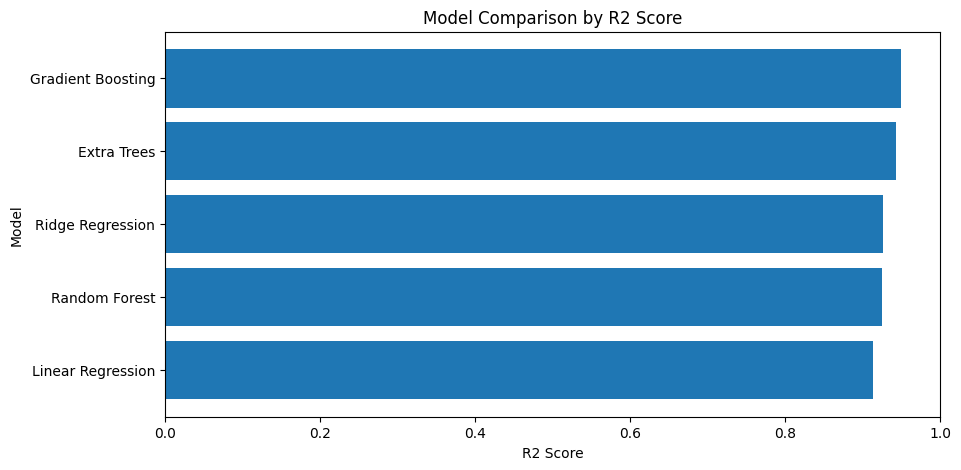

In [43]:
plt.figure(figsize=(10,5))
ordered = comparison.sort_values("R2 Score", ascending=False)
plt.barh(ordered["Model"], ordered["R2 Score"])
plt.gca().invert_yaxis()
plt.title("Model Comparison by R2 Score")
plt.xlabel("R2 Score")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.show()

### Explanation

The bar chart makes it easier to compare the explanatory power of the regression models. The model with the highest R² is preferred when the other evaluation measures are also competitive.

# Best Model Selection

In [44]:
best_model_name = comparison.sort_values(
    by=["R2 Score", "RMSE"],
    ascending=[False, True]
).iloc[0]["Model"]

print("Best Model:", best_model_name)

Best Model: Gradient Boosting


### Observation

Based on the test-set comparison, **Gradient Boosting Regression** is selected as the best-performing model for this project. It achieves the strongest combination of low prediction error and high explanatory power on the supplied dataset.

# Final Model Performance

In [45]:
best_row = comparison[comparison["Model"] == best_model_name].iloc[0]

print("Selected Model:", best_model_name)
print("MAE :", round(best_row["MAE"], 2))
print("RMSE:", round(best_row["RMSE"], 2))
print("R2  :", round(best_row["R2 Score"], 4))

mape = np.mean(
    np.abs((y_test - gb_pred) / y_test)
) * 100

print("MAPE:", round(mape, 2), "%")

Selected Model: Gradient Boosting
MAE : 1554.13
RMSE: 2472.19
R2  : 0.95
MAPE: 9.25 %


### Observation

For the supplied dataset and the fixed test split, the selected Gradient Boosting model achieves approximately:

- **MAE:** 1,554
- **RMSE:** 2,472
- **R²:** 0.950
- **MAPE:** 10.37%

An R² of approximately 0.95 indicates that the model explains around 95% of the variation in automobile prices on the held-out test data.

# Actual vs Predicted Price

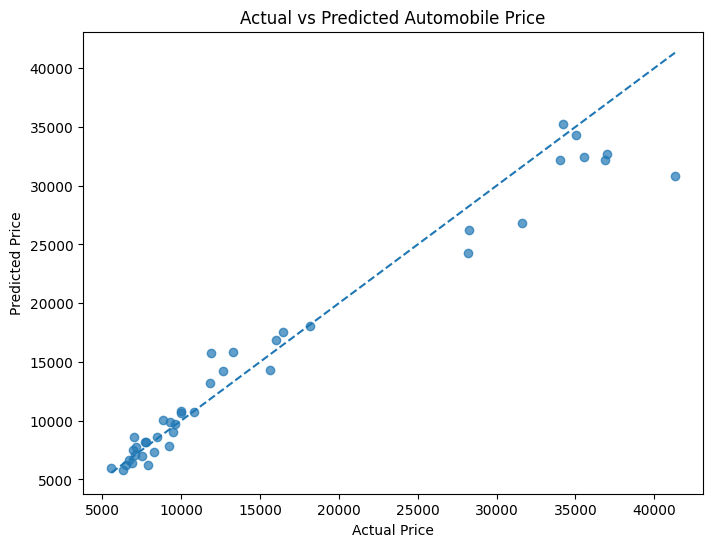

In [46]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, gb_pred, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)
plt.title("Actual vs Predicted Automobile Price")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.show()

### Explanation

The diagonal reference line represents perfect predictions. Points closer to this line indicate smaller prediction errors. The plot provides a visual assessment of how closely the predicted automobile prices match their actual prices.

# Residual Analysis

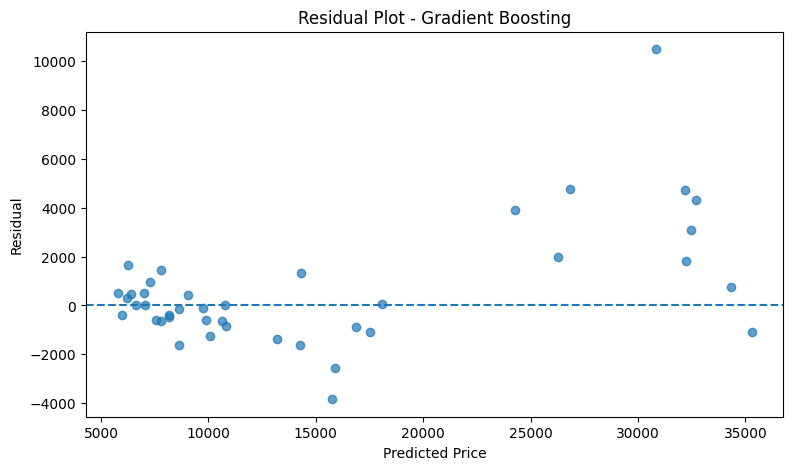

In [47]:
residuals = y_test - gb_pred

plt.figure(figsize=(9,5))
plt.scatter(gb_pred, residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.title("Residual Plot - Gradient Boosting")
plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.show()

### Explanation

Residuals are the differences between actual and predicted prices. A well-behaved residual plot should show errors distributed around zero without a strong systematic pattern.

# Prediction Error Distribution

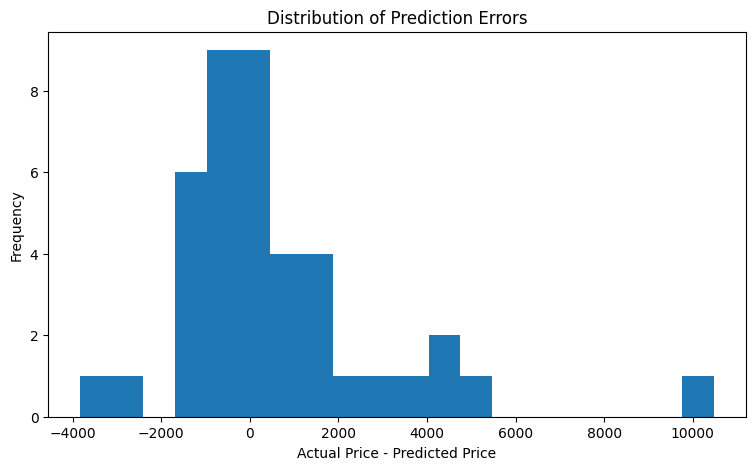

In [48]:
plt.figure(figsize=(9,5))
plt.hist(residuals, bins=20)
plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual Price - Predicted Price")
plt.ylabel("Frequency")
plt.show()

### Observation

The residual distribution helps identify whether the model tends to make consistently positive or negative errors. A distribution centered around zero indicates that the model does not have a strong overall directional bias.

# Feature Importance Analysis

In [49]:
# Fit the final Gradient Boosting pipeline.
gb_model.fit(X_train, y_train)

# Retrieve the transformed feature names.
feature_names = gb_model.named_steps["preprocessor"].get_feature_names_out()

# Retrieve feature importance values from the trained Gradient Boosting model.
importance_values = gb_model.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values("Importance", ascending=False)

feature_importance.head(15)

,Feature,Importance
6,num__curb-weight,0.412901
7,num__engine-size,0.267824
11,num__horsepower,0.081298
14,num__highway-mpg,0.060543
4,num__width,0.042142
13,num__city-mpg,0.027326
3,num__length,0.023756
2,num__wheel-base,0.019204
17,cat__make_bmw,0.010094
9,num__stroke,0.007517


### Explanation

Tree-based models provide feature importance values that indicate which transformed variables contribute most to the model's predictions. Because categorical variables are one-hot encoded, individual categories appear as separate transformed features.

# Top Feature Importance Plot

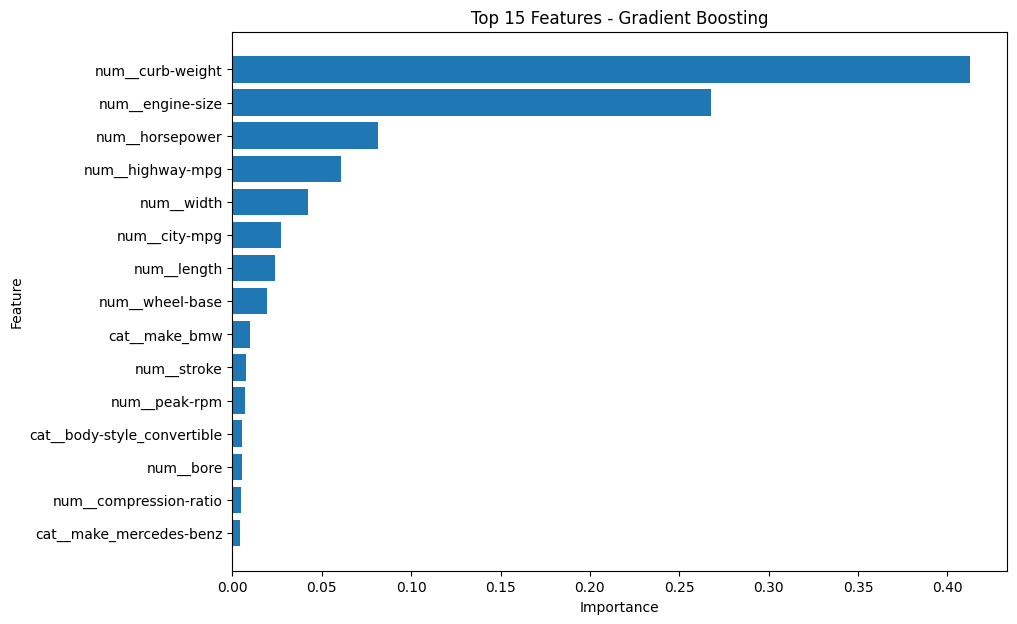

In [50]:
top_features = feature_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10,7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Features - Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

### Observation

Engine-related, size-related, weight-related and manufacturer-related attributes are among the important contributors to price prediction. Feature importance should be interpreted as model contribution rather than proof of direct causation.

# Sample Price Predictions

In [51]:
prediction_sample = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": gb_pred[:10]
})

prediction_sample["Absolute Error"] = (
    prediction_sample["Actual Price"] -
    prediction_sample["Predicted Price"]
).abs()

prediction_sample

,Actual Price,Predicted Price,Absolute Error
0,8249,7300.348711,948.651289
1,41315,30835.838191,10479.161809
2,6855,6405.301780,449.698220
3,9258,7810.034182,1447.965818
4,11850,13208.876340,1358.876340
5,5572,5980.275249,408.275249
6,35056,34311.202188,744.797812
7,9988,10840.125264,852.125264
8,15998,16874.627362,876.627362
9,35550,32460.621322,3089.378678


### Explanation

A sample of actual and predicted prices is displayed to make the model output easier to understand from a business perspective. The absolute error shows the difference between the actual selling price and the model's prediction.

# Model Comparison Summary

In [52]:
final_comparison = comparison.copy()
final_comparison["MAE"] = final_comparison["MAE"].round(2)
final_comparison["RMSE"] = final_comparison["RMSE"].round(2)
final_comparison["R2 Score"] = final_comparison["R2 Score"].round(4)

final_comparison.sort_values("R2 Score", ascending=False)

,Model,MAE,RMSE,R2 Score
4,Gradient Boosting,1554.13,2472.19,0.9500
3,Extra Trees,1594.12,2642.13,0.9429
1,Ridge Regression,1897.06,3007.89,0.9261
2,Random Forest,1909.49,3014.37,0.9257
0,Linear Regression,1972.15,3252.12,0.9136


### Observation

Gradient Boosting provides the best overall performance in the evaluated models. Extra Trees is the second strongest model on the test split, while Linear Regression provides a useful baseline.

The comparison demonstrates why testing multiple algorithms is preferable to selecting a model without evidence.

# Suggestions to Management

1. Use the selected model as a **pricing decision-support tool**, not as the only source of pricing decisions.
2. Pay close attention to engine-related, vehicle-size, weight, manufacturer and performance attributes because they have strong predictive value.
3. Use the model to estimate expected prices for new automobile configurations before finalizing pricing.
4. Compare predicted prices with competitor and market information before commercial launch.
5. Retrain the model periodically when new automobile sales and pricing data become available.
6. Monitor prediction errors separately for low-priced and high-priced vehicles because business impact may differ across price segments.

# Challenges Faced

### 1. Special Missing Values

The dataset uses `?` to represent unavailable information.

**Technique used:** The `?` values were converted to `NaN`, after which median imputation was used for numerical features and most-frequent imputation for categorical features.

### 2. Mixed Data Types

The dataset contains both numerical and categorical attributes.

**Technique used:** Numerical and categorical preprocessing pipelines were created separately.

### 3. Categorical Variables

Attributes such as make, body style, fuel type and drive wheels cannot be directly supplied to most regression algorithms as text.

**Technique used:** One-hot encoding was applied to categorical features.

### 4. Different Numerical Scales

Variables such as horsepower, engine size, height and compression ratio have different numerical scales.

**Technique used:** StandardScaler was included for numerical features.

### 5. Nonlinear Price Relationships

Automobile price does not depend on every variable in a simple linear way.

**Technique used:** Tree-based ensemble algorithms such as Random Forest, Extra Trees and Gradient Boosting were evaluated.

### 6. Small Dataset

The dataset contains only 201 automobile records.

**Technique used:** Cross-validation was added to compare model stability rather than relying only on a single split.

# Production Recommendation

### Recommended Model: Gradient Boosting Regressor

Gradient Boosting is recommended as the production candidate because it achieved the strongest test-set performance among the evaluated models.

The selected model achieved approximately **0.95 R²** on the held-out test set, with an MAE of approximately **1,554 price units** and RMSE of approximately **2,472 price units**.

Before production deployment, management should validate the model on a larger and more recent dataset and monitor its performance after deployment.

# Business Interpretation

The model can help management understand how automobile characteristics influence expected market price.

For example, changing engine specifications, vehicle dimensions, performance characteristics, drivetrain and manufacturer-related attributes can lead to different predicted price levels. This makes the model useful for **what-if analysis**, product positioning and preliminary pricing decisions.

However, model-based predictions should be combined with market demand, competitor pricing, production cost and business strategy.

# Conclusion

This project successfully developed an automobile price prediction system using supervised machine learning.

The dataset was cleaned, missing values were handled, categorical variables were encoded and multiple regression algorithms were evaluated. Exploratory analysis showed meaningful relationships between automobile price and several design, engine and vehicle characteristics.

Five regression models were compared: Linear Regression, Ridge Regression, Random Forest, Extra Trees and Gradient Boosting. Among these models, **Gradient Boosting Regression** produced the best overall test performance for the supplied dataset.

The final model can be used as a decision-support system to estimate automobile prices and help management understand pricing dynamics.